# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss

DATA_PATH = Path("data/matched_saturdays.csv")
EXPECTED_SHA256 = "4BA7F83563670174BE36BDB83035CBC1D0067981F65E8201F75F84CCD231F808"
actual_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert actual_sha256 == EXPECTED_SHA256, f"Data hash mismatch: {actual_sha256}"

df = pd.read_csv(DATA_PATH)
df["saturday"] = pd.to_datetime(df["saturday"])
df["observation_date"] = pd.to_datetime(df["observation_date"])
df["rain_0_01in"] = pd.to_numeric(df["rain_0_01in"], errors="coerce")
df["precipitation_in"] = pd.to_numeric(df["precipitation_in"], errors="coerce")


## Question

**Question.** How well do FridayÃ¢â‚¬â„¢s archived NOAA NBM rain probabilities estimate whether the CoCoRaHS Sunday-morning report following a Saturday records at least 0.01 in of rain in Fairfax?

**Quantity.** Probability (0Ã¢â‚¬â€œ1) of a wet CoCoRaHS 24-hour report ending Sunday morning for a Saturday forecast decision.

The intended action is whether to rent a 10Ãƒâ€”20 canopy. This is a decision scenario; the report is a proxy for rain during the class, not a direct class-hour measurement. The layer diagram is `fig/layers.png`.

![Layer diagram](fig/layers.png)


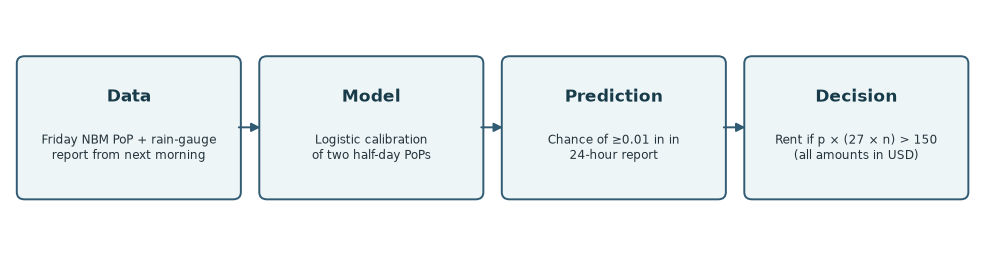

In [2]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(10, 2.7))
ax.set_xlim(0, 10)
ax.set_ylim(0, 2.7)
ax.axis("off")
boxes = [
    (0.15, "Data", "Friday NBM PoP + rain-gauge\nreport from next morning"),
    (2.65, "Model", "Logistic calibration\nof two half-day PoPs"),
    (5.15, "Prediction", "Chance of ≥0.01 in in\n24-hour report"),
    (7.65, "Decision", "Rent if p × (27 × n) > 150\n(all amounts in USD)"),
]
for x, title, body in boxes:
    patch = FancyBboxPatch((x, 0.65), 2.15, 1.45,
                           boxstyle="round,pad=0.08,rounding_size=0.08",
                           linewidth=1.4, edgecolor="#315b72", facecolor="#eef5f7")
    ax.add_patch(patch)
    ax.text(x + 1.075, 1.72, title, ha="center", va="center", fontsize=12, weight="bold", color="#183b4a")
    ax.text(x + 1.075, 1.15, body, ha="center", va="center", fontsize=8.5, color="#24343b")
for x in (2.33, 4.83, 7.33):
    ax.add_patch(FancyArrowPatch((x, 1.38), (x + 0.28, 1.38), arrowstyle="-|>", mutation_scale=13,
                                 linewidth=1.4, color="#315b72"))
fig.tight_layout()
fig.savefig("fig/layers.png", dpi=160, bbox_inches="tight")
plt.show()


## Data

The matched file contains one candidate Saturday per row. The observation is the next morningÃ¢â‚¬â„¢s daily report at CoCoRaHS station VA-FX-121, Fairfax 3.2 W. NOAA inputs are two NBM NBE P12 forecasts for KIAD: 12-hour precipitation probabilities for periods ending Sunday 00Z and 12Z, issued Friday at 13Z. The station forecast is about 14 km from the gauge. The observation period is shifted by about an hour from the UTC forecast windows and includes rain outside class hours.

`data/README.md` documents sources, terms, reconstruction, and the SHA-256 checked above. The raw plot and summary table below precede all modeling.


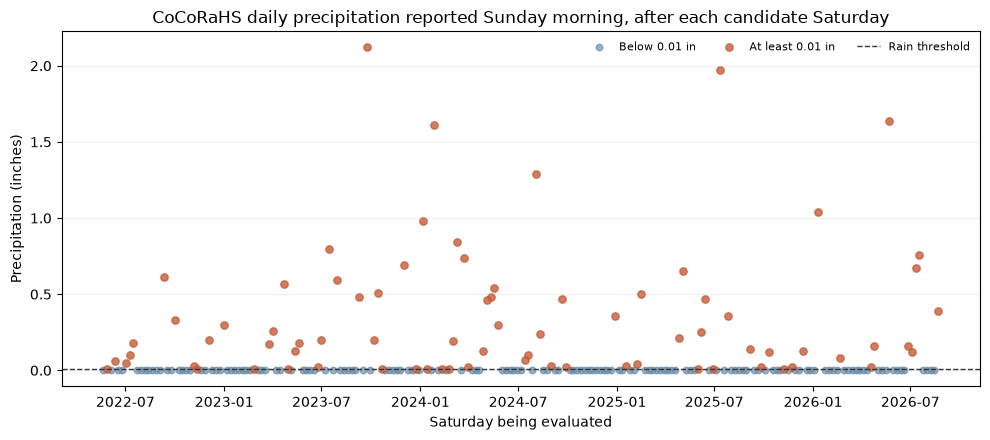

,Raw-data summary,Value
0,Candidate Saturdays,223
1,Complete observation/forecast pairs,222
2,Missing CoCoRaHS outcomes,1
3,Wet reports (>= 0.01 in),78
4,Wet-report rate,35.1%
5,Mean reported precipitation,0.125 in
6,Median reported precipitation,0.00 in
7,First / last candidate Saturday,2022-05-21 / 2026-08-22
8,Reports at 7:00 a.m. local,221
9,Reports at another time,1


In [3]:
# Raw observation plot and summary (before modeling)

paired = df.dropna(subset=["rain_0_01in", "precipitation_in"]).copy()
fig, ax = plt.subplots(figsize=(10, 4.5))
wet = paired["rain_0_01in"].eq(1)
ax.scatter(paired.loc[~wet, "saturday"], paired.loc[~wet, "precipitation_in"],
           s=22, alpha=0.7, color="#6b8eaa", label="Below 0.01 in")
ax.scatter(paired.loc[wet, "saturday"], paired.loc[wet, "precipitation_in"],
           s=28, alpha=0.8, color="#c45d3a", label="At least 0.01 in")
ax.axhline(0.01, color="#333333", linestyle="--", linewidth=1, label="Rain threshold")
ax.set(title="CoCoRaHS daily precipitation reported Sunday morning, after each candidate Saturday",
       xlabel="Saturday being evaluated", ylabel="Precipitation (inches)")
ax.legend(frameon=False, ncol=3, fontsize=8)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
Path("fig").mkdir(exist_ok=True)
fig.savefig("fig/raw_rainfall.png", dpi=160, bbox_inches="tight")
plt.show()

summary = pd.DataFrame([
    ("Candidate Saturdays", len(df)),
    ("Complete observation/forecast pairs", len(paired)),
    ("Missing CoCoRaHS outcomes", int(df["rain_0_01in"].isna().sum())),
    ("Wet reports (>= 0.01 in)", int(paired["rain_0_01in"].sum())),
    ("Wet-report rate", f"{paired['rain_0_01in'].mean():.1%}"),
    ("Mean reported precipitation", f"{paired['precipitation_in'].mean():.3f} in"),
    ("Median reported precipitation", f"{paired['precipitation_in'].median():.2f} in"),
    ("First / last candidate Saturday", f"{df['saturday'].min().date()} / {df['saturday'].max().date()}"),
    ("Reports at 7:00 a.m. local", int(paired["observation_time_local"].eq("07:00 AM").sum())),
    ("Reports at another time", int((~paired["observation_time_local"].eq("07:00 AM")).sum())),
], columns=["Raw-data summary", "Value"])
display(summary)


## Split

Use a chronological split because the decision is about future Saturdays. Fit on complete records through 2025-12-27 and hold out all complete records from 2026-01-03 onward. Do not use 2026 to fit, select, or tune the model. One candidate Sunday report (2026-01-18) is missing and stays missing rather than being imputed.


In [4]:
FEATURES = ["p12_ending_00z_sunday_pct", "p12_ending_12z_sunday_pct"]
complete = df.dropna(subset=["rain_0_01in", *FEATURES]).copy()
train = complete[complete["saturday"] < "2026-01-01"].copy()
test = complete[complete["saturday"] >= "2026-01-01"].copy()
X_train = train[FEATURES].to_numpy() / 100.0
y_train = train["rain_0_01in"].astype(int).to_numpy()
X_test = test[FEATURES].to_numpy() / 100.0
y_test = test["rain_0_01in"].astype(int).to_numpy()

print(f"Training: {len(train)} Saturdays, {y_train.sum()} wet reports, "
      f"{train.saturday.min().date()} through {train.saturday.max().date()}")
print(f"Held out: {len(test)} Saturdays, {y_test.sum()} wet reports, "
      f"{test.saturday.min().date()} through {test.saturday.max().date()}")
print("NBM versions in training:", ", ".join(sorted(train["nbm_version"].unique())))
print("NBM versions in held-out set:", ", ".join(sorted(test["nbm_version"].unique())))


Training: 189 Saturdays, 68 wet reports, 2022-05-21 through 2025-12-27
Held out: 33 Saturdays, 10 wet reports, 2026-01-03 through 2026-08-22
NBM versions in training: V4.0, V4.1, V4.2, V4.3
NBM versions in held-out set: V4.3, V5.0


## Baseline

The baseline predicts the training-set wet-report frequency for every held-out Saturday. This is a no-information climatology benchmark. It is scored using the same canopy decision rule and held-out outcomes as the NBM-based model.


In [5]:
baseline_probability = y_train.mean()
baseline_test_probability = np.repeat(baseline_probability, len(test))
print(f"Training wet-report rate used as baseline probability: {baseline_probability:.3f}")


Training wet-report rate used as baseline probability: 0.360


## Model

Fit a two-input logistic calibration on training data only:

$$\operatorname{logit}(p_i)=eta_0+eta_1 x_{i,00Z}+eta_2 x_{i,12Z},$$

where $x_{i,00Z}$ and $x_{i,12Z}$ are the NBM P12 probabilities (as fractions) for the 12-hour periods ending Sunday 00Z and 12Z. The coefficients describe how those forecast probabilities relate to the chance that the full CoCoRaHS daily report is wet. L2 regularization is used (`C=1`). The least-trusted assumption is that this relationship remains stable across NBM versions, seasons, and the airport-to-gauge distance.

The forecast probabilities are two marginal half-day probabilities; the logistic fit learns their relationship to the daily event instead of assuming the two periods are independent.


In [6]:
model = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000)
model.fit(X_train, y_train)
model_test_probability = model.predict_proba(X_test)[:, 1]

coef = pd.DataFrame({
    "Term": ["Intercept", "Sunday 00Z P12 (per 1.00 probability)", "Sunday 12Z P12 (per 1.00 probability)"],
    "Estimate": [model.intercept_[0], model.coef_[0, 0], model.coef_[0, 1]],
})
display(coef.round(3))
print(f"Held-out Brier score, climatology: {brier_score_loss(y_test, baseline_test_probability):.3f}")
print(f"Held-out Brier score, calibrated NBM: {brier_score_loss(y_test, model_test_probability):.3f}")

# Decision loss scenario: renting costs $150; without a canopy, a wet report
# risks $27 of gross revenue per paid attendee. These are scenario inputs.
def policy_score(probabilities, y, attendees):
    threshold = 150 / (27 * attendees)
    rent = probabilities >= threshold
    realized_cost = np.where(rent, 150, np.where(y == 1, 27 * attendees, 0))
    return threshold, rent, realized_cost

rows = []
for attendees in (6, 8, 10):
    threshold, rent_base, cost_base = policy_score(baseline_test_probability, y_test, attendees)
    _, rent_model, cost_model = policy_score(model_test_probability, y_test, attendees)
    rows.extend([
        {"Paid attendees (scenario)": attendees, "Probability threshold": threshold,
         "Method": "Training-rate baseline", "Canopy rentals": int(rent_base.sum()),
         "Held-out total cost ($)": int(cost_base.sum()), "Mean cost per Saturday ($)": cost_base.mean()},
        {"Paid attendees (scenario)": attendees, "Probability threshold": threshold,
         "Method": "Calibrated NBM", "Canopy rentals": int(rent_model.sum()),
         "Held-out total cost ($)": int(cost_model.sum()), "Mean cost per Saturday ($)": cost_model.mean()},
    ])
score_table = pd.DataFrame(rows)
display(score_table.round({"Probability threshold": 3, "Mean cost per Saturday ($)": 2}))

primary = score_table[score_table["Paid attendees (scenario)"].eq(8)].set_index("Method")
print(f"At 8 attendees, the held-out mean decision cost was "
      f"${primary.loc['Training-rate baseline', 'Mean cost per Saturday ($)']:.2f} per Saturday "
      f"for the baseline and ${primary.loc['Calibrated NBM', 'Mean cost per Saturday ($)']:.2f} "
      f"for the calibrated NBM model (33 held-out Saturdays).")
print("The 2026 estimate is preliminary: only 33 Saturdays are held out, and the model version and local rainfall may differ from training.")


,Term,Estimate
0,Intercept,-2.018
1,Sunday 00Z P12 (per 1.00 probability),3.517
2,Sunday 12Z P12 (per 1.00 probability),2.642


Held-out Brier score, climatology: 0.214
Held-out Brier score, calibrated NBM: 0.094


,Paid attendees (scenario),Probability threshold,Method,Canopy rentals,Held-out total cost ($),Mean cost per Saturday ($)
0,6,0.926,Training-rate baseline,0,1620,49.09
1,6,0.926,Calibrated NBM,5,1560,47.27
2,8,0.694,Training-rate baseline,0,2160,65.45
3,8,0.694,Calibrated NBM,8,1848,56.00
4,10,0.556,Training-rate baseline,0,2700,81.82
5,10,0.556,Calibrated NBM,9,2160,65.45


At 8 attendees, the held-out mean decision cost was $65.45 per Saturday for the baseline and $56.00 for the calibrated NBM model (33 held-out Saturdays).
The 2026 estimate is preliminary: only 33 Saturdays are held out, and the model version and local rainfall may differ from training.


## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.
